# Solution 8.3: Attention in RNN

In this lab you will explore the use of a attention for context aggregation in an RNN.  We will use a very simplified language translation task for our experiment.

While English language sentences generally use **subject verb object** order, in Spanish the order is flexible and can change based on what the speaker wants to emphasize.  Here we will translate Spanish **object verb spanish** phrases to English **subject verb object** phrases.  The translation model must both translate words and reorder them.

Here we use `<EOS>` to indicate the end of a sentence.

Example: `gato mira perro <EOS>` → `dog sees cat <EOS>`.

In [20]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(1234)
random.seed(1234)
np.random.seed(1234)
device = 'mps' if torch.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)

Using: mps


First we will build our source and target language vocabularies.

In [21]:
SRC_NOUNS = ['gato', 'perro', 'pajaro', 'pez', 'caballo', 'raton']
TGT_NOUNS = ['cat', 'dog', 'bird', 'fish', 'horse', 'mouse']
SRC_VERBS = ['mira', 'persigue', 'ayuda', 'visita']
TGT_VERBS = ['sees', 'chases', 'helps', 'visits']
EOS, SOS= '<EOS>', '<SOS>'

Now we create dictionaries which map words to token ids, and token ids back to words.

In [22]:
src_tokens = SRC_NOUNS + SRC_VERBS + [EOS]
tgt_tokens = TGT_NOUNS + TGT_VERBS + [EOS, SOS]
src_to_id = {w:i for i, w in enumerate(src_tokens)}
tgt_to_id = {w:i for i, w in enumerate(tgt_tokens)}
id_to_src = {i:w for w,i in src_to_id.items()}
id_to_tgt = {i:w for w,i in tgt_to_id.items()}
SRC_EOS = src_to_id[EOS]
TGT_EOS, TGT_SOS = tgt_to_id[EOS], tgt_to_id[SOS]

print('source vocabulary:', src_to_id)
print('target vocabulary:', tgt_to_id)

source vocabulary: {'gato': 0, 'perro': 1, 'pajaro': 2, 'pez': 3, 'caballo': 4, 'raton': 5, 'mira': 6, 'persigue': 7, 'ayuda': 8, 'visita': 9, '<EOS>': 10}
target vocabulary: {'cat': 0, 'dog': 1, 'bird': 2, 'fish': 3, 'horse': 4, 'mouse': 5, 'sees': 6, 'chases': 7, 'helps': 8, 'visits': 9, '<EOS>': 10, '<SOS>': 11}


The `make_batch` function will create a random batch of tokenized translation examples.

In [23]:
def make_batch(batch_size):
    """ Make a batch of random sentence translations.
        Returns: source and target token sequences, each of size (batch_size,4)
    """
    # Select random source subjects and objects
    subjects = torch.randint(len(SRC_NOUNS), (batch_size,))
    objects = torch.randint(len(SRC_NOUNS), (batch_size,))

    # Make sure subject and object are different
    objects = torch.where(objects == subjects, (objects + 1) % len(SRC_NOUNS), objects)

    # Select random verbs
    verbs = torch.randint(len(SRC_VERBS), (batch_size,))

    # Build tensors
    src = torch.stack([objects, verbs + len(SRC_NOUNS), subjects,
                       torch.full_like(subjects, SRC_EOS)], dim=1)
    tgt = torch.stack([subjects, verbs + len(TGT_NOUNS), objects,
                       torch.full_like(subjects, TGT_EOS)], dim=1)
    
    return src.to(device), tgt.to(device)

def words(row, dictionary):
    return [dictionary[int(x)] for x in row.detach().cpu()]

src, tgt = make_batch(1)
print('source:', words(src[0], id_to_src))
print('target:', words(tgt[0], id_to_tgt))

source: ['caballo', 'ayuda', 'pez', '<EOS>']
target: ['fish', 'helps', 'horse', '<EOS>']


We will use an encoder-decoder sequence-to-sequence design.

The `Encoder` combines a token embedding and a GRU model.  It takes the source sequence and produces a sequence of "key" vectors and the final hidden state.

In [24]:
class Encoder(nn.Module):
    def __init__(self, embed_dim=32, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(len(src_tokens), embed_dim)
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
    
    def forward(self, src):
        """ Run encoder on sequence of tokens.

            Arguments:
                src: Input tokens (B,L)
            
            Returns: Output (B,L,H) and final hidden states (1,B,H)
        """
        return self.rnn(self.embedding(src))

In [25]:
encoder = Encoder()
keys, hidden = encoder(torch.randint(len(src_tokens),(32,4)))
keys.shape, hidden.shape

(torch.Size([32, 4, 64]), torch.Size([1, 32, 64]))

The `AdditiveAttention` class implements additive attention from the Bahdenau paper.  It takes the sequence of keys from the encoder and a query vector (the current hidden state of the decoder).  The attention score for each key is computed as:

$$ s_i = W_e( \textrm{tanh}( W_k k_i + W_q q) ) $$

Then the attention weights are computed using softmax on the scores:

$$ a_1,\ldots,a_n = \textrm{softmax}(s_1,\ldots,s_n)$$

Finally we compute the context vector as a weighted sum of the key vectors:

$$ c = \sum_i a_i k_i $$


In [26]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.key_layer = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.query_layer = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.energy_layer = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, query, keys):
        """ Compute additive attention (Bahdanau attention)

            Arguments:
                query: query vector (B,H)
                keys: sequence of encoder keys (B,L,H)

            Returns:
                aggregated context vector (B,H) and attention weights (B,L)
        """
        # Compute attention scores from keys and query (B,L)
        scores = self.energy_layer(torch.tanh(
            self.key_layer(keys) + self.query_layer(query).unsqueeze(1)
        )).squeeze(-1)

        # Convert to attention mask (logits) using softmax (B,L)
        weights = torch.softmax(scores, dim=1)

        # Apply attention mask to keys (B,H)
        context = torch.sum(weights.unsqueeze(-1) * keys,dim=1)
        
        return context, weights

In [27]:
attention = AdditiveAttention(hidden_dim=2)
context, weights = attention(torch.randn(1,2),torch.randn(1,4,2))
context.shape, weights.shape

(torch.Size([1, 2]), torch.Size([1, 4]))

The `EncoderDecoder` implements an encoder-decoder that does not use attention.  

The encoder first processes the input sequence and produces a sequence of keys and a final hidden state.  The decoder then generates the output tokens one by one, using the final hidden state of the encoder as its initial hidden state.

In [28]:
class EncoderDecoder(nn.Module):
    def __init__(self, seq_length=4, embed_dim=32, hidden_dim=64):
        super().__init__()
        self.seq_length = seq_length
        self.encoder = Encoder(embed_dim, hidden_dim)
        self.target_embedding = nn.Embedding(len(tgt_tokens), embed_dim)
        self.decoder = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, len(tgt_tokens))

    def forward(self, src, target=None):
        """ Run encoder-decoder language translator.

            Arguments:
                src: source tokens (B,L)
                target: Optional target sequence for teacher forcing (B,L)

            Returns:
                Output logits (B,target_vocab_size)
        """
        # Encode source sequence
        keys, hidden = self.encoder(src)

        # Make a batch of start tokens
        batch = src.size(0)
        token = torch.full((batch, 1), TGT_SOS, dtype=torch.long, device=src.device)

        # Generate output token by token
        logits = []
        for t in range(self.seq_length):
            # Get target embedding for current token
            decoder_input = self.target_embedding(token) # (B,1,H)

            # Run decoder, updating the hidden state so that we can use it for the next iteration
            out, hidden = self.decoder(decoder_input, hidden) # (B,1,H)

            # Get output logits
            step_logits = self.output(out[:, 0]) # (B,1,T)

            # Append to list of output logits
            logits.append(step_logits)

            # Get next token either from target sequence (for teacher forcing) or from current output
            token = target[:, t:t+1] if target is not None else step_logits.argmax(-1, keepdim=True)

        # Stack output logits
        logits = torch.stack(logits, dim=1)
        
        return logits

This version includes attention.  At each step of the decoder, we use attention to combine the encoder keys with the query (the decoder's current hidden state) and produce a context vector.  The context vector is concatenated with the input to the decoder when producing the next hidden state and the decoder output.  

In [29]:
class EncoderDecoderWithAttention(nn.Module):
    def __init__(self, seq_length=4, embed_dim=32, hidden_dim=64):
        super().__init__()
        self.seq_length = seq_length
        self.encoder = Encoder(embed_dim, hidden_dim)
        self.attention = AdditiveAttention(hidden_dim)
        self.target_embedding = nn.Embedding(len(tgt_tokens), embed_dim)
        self.decoder = nn.GRU(embed_dim + hidden_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(2 * hidden_dim, len(tgt_tokens))

    def forward(self, src, target=None, return_attention=False):
        """ Run encoder-decoder language translator.

            Arguments:
                src: source tokens (B,L)
                target: Optional target sequence for teacher forcing (B,L)
                return_attention: Whether to output the attention masks

            Returns:
                Output logits (B,target_vocab_size), attention masks (B,L,L) if return_attention=True
        """
        # Encode source sequence
        keys, hidden = self.encoder(src)

        # Make a batch of start tokens
        batch = src.size(0)
        token = torch.full((batch, 1), TGT_SOS, dtype=torch.long, device=src.device)

        # Generate output token by token
        logits, all_weights = [], []
        for t in range(self.seq_length):
            # Apply attention with current hidden state as query to get context vector
            context, weights = self.attention(hidden[-1], keys) # (B,H), (B,L)

            # Concatenate context vector with target embedding for current token
            decoder_input = torch.cat([self.target_embedding(token), context.unsqueeze(1)], dim=-1) # (B,2*H)

            # Run decoder, updating the hidden state so that we can use it for the next iteration
            out, hidden = self.decoder(decoder_input, hidden) # (B,1,H)

            # Concatenate decoder output with context vector and make output logits
            step_logits = self.output(torch.cat([out[:, 0], context], dim=-1)) # (B,T)

            # Append to list of output logits and list of attention weights
            logits.append(step_logits)
            all_weights.append(weights)

            # Get next token either from target sequence (for teacher forcing) or from current output
            token = target[:, t:t+1] if target is not None else step_logits.argmax(-1, keepdim=True)

        # Stack output logits and attention weights
        logits = torch.stack(logits, dim=1)
        weights = torch.stack(all_weights, dim=1)

        return (logits, weights) if return_attention else logits

Here are functions to train and test the models.

In [30]:
def train(model, updates=1200, batch_size=96, lr=3e-3):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    losses = []
    for step in range(updates):
        src, tgt = make_batch(batch_size)
        optimizer.zero_grad()
        logits = model(src, tgt)
        loss = loss_fn(logits.reshape(-1, len(tgt_tokens)), tgt.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
    return losses

In [31]:
@torch.no_grad()
def accuracy(model, examples=1000):
    model.eval()
    src, tgt = make_batch(examples)
    pred = model(src).argmax(-1)
    return pred.eq(tgt).all(dim=1).float().mean().item()

In [32]:
@torch.no_grad()
def test_model(model,return_attention=False):
    model.eval()
    src, tgt = make_batch(1)
    if return_attention:
        logits, attention = model(src,return_attention=True)
    else:
        logits = model(src)
    pred = logits.argmax(-1)[0]
    src_words = words(src[0], id_to_src)
    tgt_words = words(tgt[0], id_to_tgt)
    pred_words = words(pred, id_to_tgt)
    if return_attention:
        return src_words, tgt_words, pred_words, attention
    else:
        return src_words, tgt_words, pred_words


The `show_translation` function runs the model on an example translation task and shows the results as well as the attention values if used.

In [33]:
@torch.no_grad()
def show_translation(model,show_attention=False):
    if show_attention:
        src_words, tgt_words, pred_words, attention = test_model(model,return_attention=True)
    else:
        src_words, tgt_words, pred_words = test_model(model)

    print('source:    ', ' '.join(src_words))
    print('target:    ', ' '.join(tgt_words))
    print('prediction:', ' '.join(pred_words))

    if show_attention:
        plt.figure(figsize=(6, 4))
        plt.imshow(attention[0].cpu().numpy(), cmap='magma', aspect='auto')
        plt.xticks(range(4), src_words)
        plt.yticks(range(4), tgt_words)
        plt.xlabel('source position')
        plt.ylabel('target position')
        plt.colorbar(label='attention weight')
        plt.title('Attention during translation')
        plt.show()

First we train the encoder-decoder model.  It is in fact able to learn the task without attention.

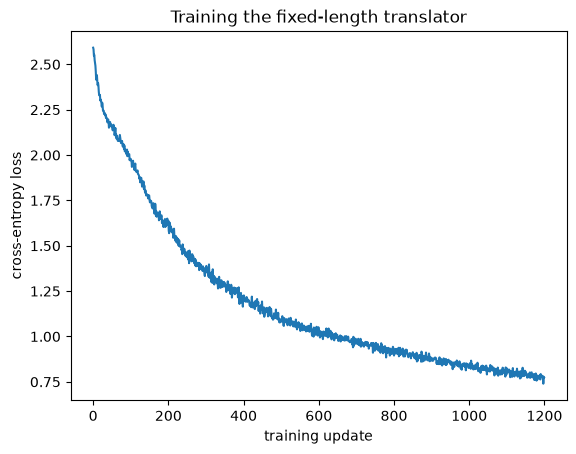

In [34]:
model = EncoderDecoder(hidden_dim=4).to(device)
losses = train(model)
plt.plot(losses)
plt.xlabel('training update'); plt.ylabel('cross-entropy loss')
plt.title('Training the fixed-length translator')
plt.show()

In [35]:
print(f'Translation accuracy: {accuracy(model):.1%}')

Translation accuracy: 16.1%


In [36]:
show_translation(model)

source:     raton visita pez <EOS>
target:     fish visits mouse <EOS>
prediction: fish visits mouse <EOS>


Now we train the attention model.  It converges a little more quickly than the model without attention.

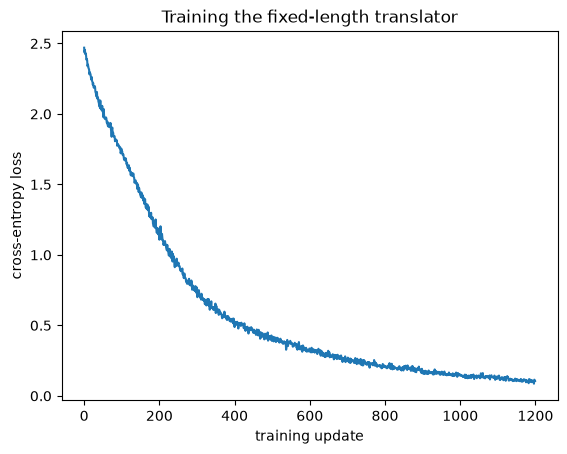

In [37]:
model = EncoderDecoderWithAttention(hidden_dim=4).to(device)
losses = train(model)
plt.plot(losses)
plt.xlabel('training update'); plt.ylabel('cross-entropy loss')
plt.title('Training the fixed-length translator')
plt.show()

source:     pajaro persigue perro <EOS>
target:     dog chases bird <EOS>
prediction: dog chases bird <EOS>


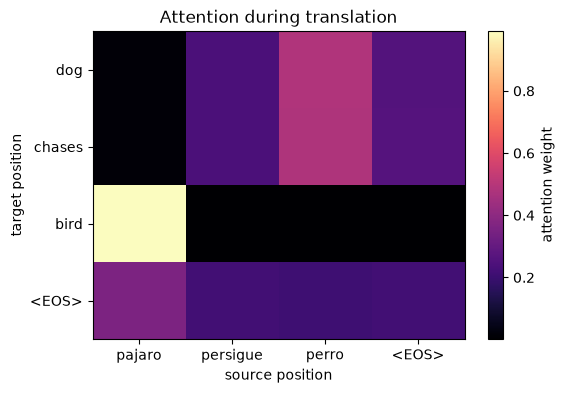

In [38]:
show_translation(model,show_attention=True)

## Discussion questions

1. Which source token has highest attention weight for each target token?  Why?

The source token associated with the target word in English, because it is understanding which words are translations for others.

2. Do the attention values add up to 1.0 across the rows or the columns?  Why?

Yes, because of the softmax function applied in the additive attention model.

3. Try reducing the hidden dimension for each model to 4.  What happens to the accuracy of each model?  Why?

It takes way longer to converge, if you can even call it converging. The model requires more depth to be fully functional, and 4 hidden dimensions is insufficient.